In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("retail_sales_dataset.csv")
df.columns = df.columns.str.strip()

print("Shape:", df.shape)
print(df.columns.tolist())
df.head()

Shape: (1000, 9)
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [2]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Describing the Dataset
#checking the data if there is any null values

df.info()
print()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [4]:
# checking the last 5 rows of the dataset
df.tail()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [5]:
# check how many rows and columns the dataset has
df.shape

(1000, 9)

In [6]:
# visualize the dataset
df.describe()


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [7]:
# Mode = the most frequeunt value in each column
num_cols = ["Transaction ID", "Age", "Quantity", "Price per Unit","Total Amount"]
df[num_cols].mode().iloc[0]

Transaction ID     1.0
Age               43.0
Quantity           4.0
Price per Unit    50.0
Total Amount      50.0
Name: 0, dtype: float64

In [8]:
# adding mode to the describe table
summary = df.describe()
summary.loc["mode"] = df[summary.columns].mode().iloc[0]
summary.round(2)

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.00,1000.00,1000.00,1000.00,1000.0
mean,500.50,41.39,2.51,179.89,456.0
std,288.82,13.68,1.13,189.68,560.0
min,1.00,18.00,1.00,25.00,25.0
25%,250.75,29.00,1.00,30.00,60.0
50%,500.50,42.00,3.00,50.00,135.0
75%,750.25,53.00,4.00,300.00,900.0
max,1000.00,64.00,4.00,500.00,2000.0
mode,1.00,43.00,4.00,50.00,50.0


In [9]:
#3. Time Series Analysis
# in this section, i convert the date colum to a proper date,
# then plot total sales by month and by quaterto see how sales chage over time
df["Date"] = pd.to_datetime(df["Date"])
print("From:", df["Date"].min(), " To:", df["Date"].max())

From: 2023-01-01 00:00:00  To: 2024-01-01 00:00:00


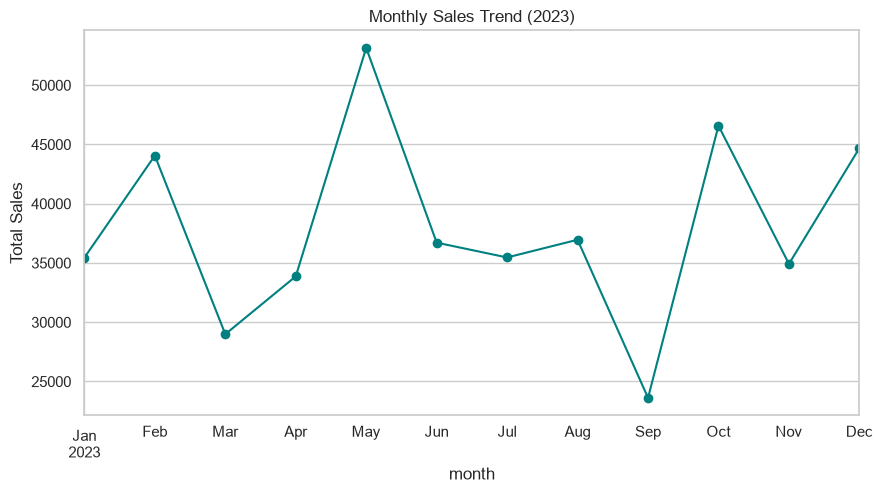

In [10]:
# keep only 2023, because 2024-01-01 is a single day and would show misleading drop
df_2023 = df[df["Date"] < " 2024-01-01"]
monthly_sales = df_2023.resample("ME", on="Date")["Total Amount"].sum()
monthly_sales.plot(marker="o", color="teal", title="Monthly Sales Trend (2023)")
plt.xlabel("month")
plt.ylabel("Total Sales")
plt.show()           


**What I found (Monthly Sales, 2023):
- Sales peaked in May at roughly 53,000, which is the strongest month of the year.
- September was the weakest month at roughly 23,500, less than half of May's sales.
- Other strong months were October (about 46,500), December (about 44,700) and February (about 44,000).
- There is no steady upward or downward trend. Sales are volatile and swing between high and low months, which suggests demand is driven by specific events or promotions.
- I excluded 1 January 2024 because it is a single day and would show a misleading drop at the end of the chart.


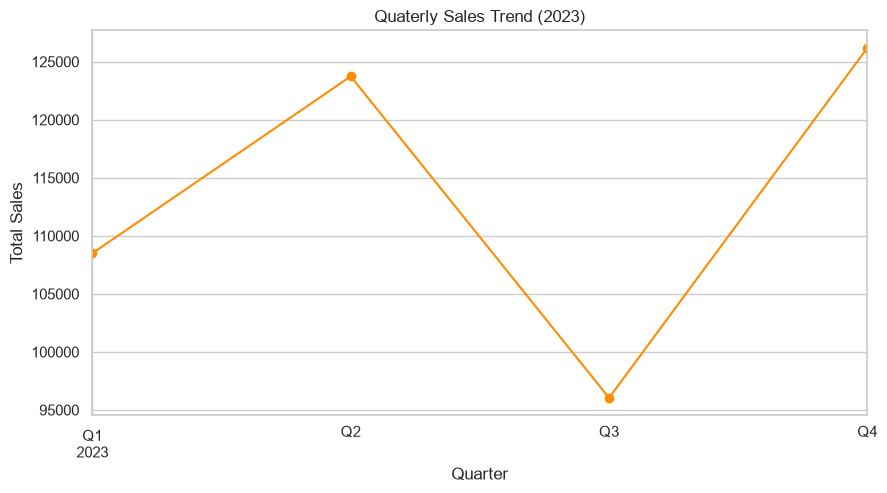

Date
2023-03-31    108500
2023-06-30    123735
2023-09-30     96045
2023-12-31    126190
Freq: QE-DEC, Name: Total Amount, dtype: int64

In [11]:
# Quaterly sales
quaterly_sales = df_2023.resample("QE", on="Date")["Total Amount"].sum()
quaterly_sales.plot(marker="o", color="darkorange", title="Quaterly Sales Trend (2023)")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.show()
quaterly_sales
                             

What I found (Quarterly Sales, 2023):
-Q4 was the strongest quarter at roughly 126,000, followed closely by Q2 at roughly 124,000.
- Q3 was the weakest quarter at roughly 96,000, driven by the sharp September dip seen in the monthly chart.
- Q1 sat in the middle at roughly 108,500.
- Sales did not grow steadily through the year. They rose from Q1 to Q2, fell sharply in Q3, then recovered to the year's highest level in Q4.
- Q4 sales were about 30% higher than Q3, which shows a strong recovery at the end of the year.

Why this matters is  Q3 slump and Q4 rebound suggest the business could plan promotions or stock to lift the weaker mid-year period, and prepare for the strong end-of-year demand.

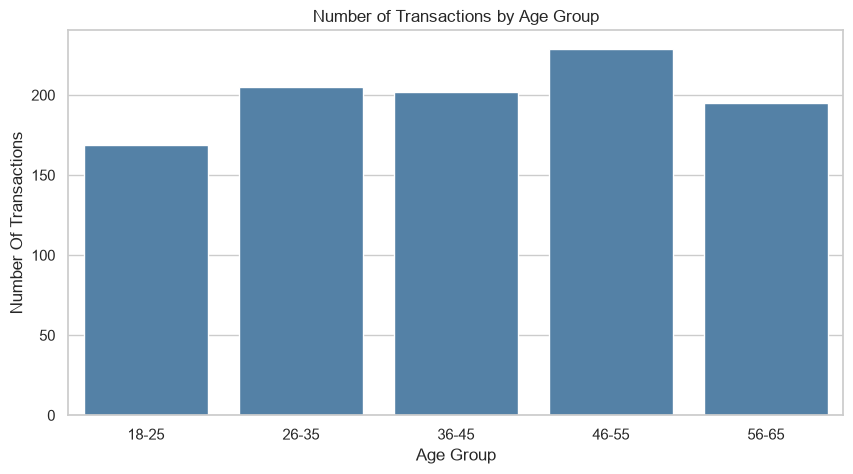

Age Group
18-25    169
26-35    205
36-45    202
46-55    229
56-65    195
Name: count, dtype: int64

In [12]:
# 4. Customer Demographics AnalysisIn this section, I group customers into age brackets and look at the gender split,
# to understand who the business is selling to.

bins = [17,25,35,45,55,65]
labels = ["18-25","26-35","36-45","46-55","56-65"]
df["Age Group"] = pd.cut(df["Age"], bins=bins, labels=labels)
sns.countplot(data=df, x="Age Group", order=labels, color="Steelblue")
plt.title("Number of Transactions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number Of Transactions")
plt.show()
df["Age Group"].value_counts().reindex(labels)




What I found (Age Groups)
- The 46-55 group has the most transactions about 23%, followed by 26-35  about 20.5% and 36-45 about 20%.
- The 18-25 group has the fewest  about 17%.
- Overall, customers are spread fairly evenly across all age groups, so the business does not depend on one age bracket.
- Note: the 18-25 bracket covers 8 years while the others cover 10, so part of its lower count is simply because it is a narrower range.

Why this matters is because the customer base is broad, marketing should not target only young shoppers. The 46-55 group is the largest segment, so it is worth checking what they buy most, which I explore in the product analysis.

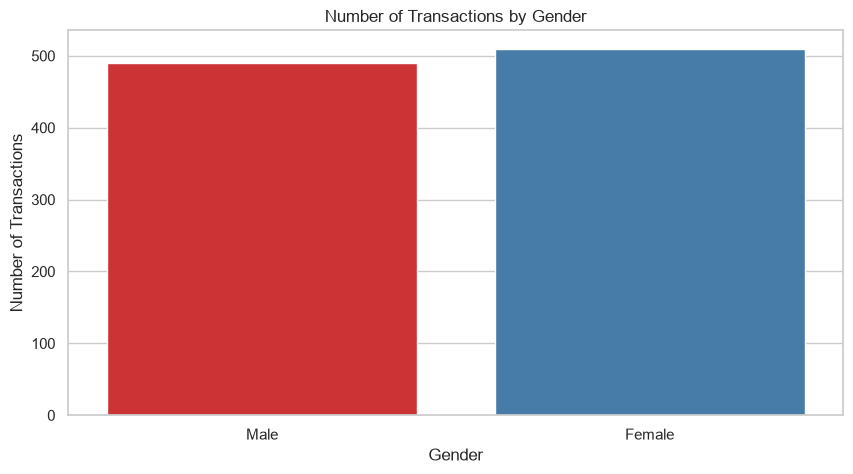

Gender
Female    510
Male      490
Name: count, dtype: int64

Gender
Female    51.0
Male      49.0
Name: proportion, dtype: float64


In [13]:
# count transacytions by gender
sns.countplot(data=df, x="Gender", hue="Gender", palette="Set1", legend=False)
plt.title("Number of Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.show()
print(df["Gender"].value_counts())
print()
print((df["Gender"].value_counts(normalize=True) * 100).round(1))


What I found (Gender Breakdown)
- Female customers made 510 transactions (51%) and male customers made 490 (49%).
- The split is almost even, with only a 2 percentage point difference.
- This chart counts transactions, not money spent, so it shows how often each group buys rather than how much they spend.

Why this matters is the customer base is balanced between men and women, so the business should not build its marketing around one gender. A better question is whether the two groups buy different product categories or spend different amounts, which I look at in the product analysis.

<StringArray>
['Beauty', 'Clothing', 'Electronics']
Length: 3, dtype: str



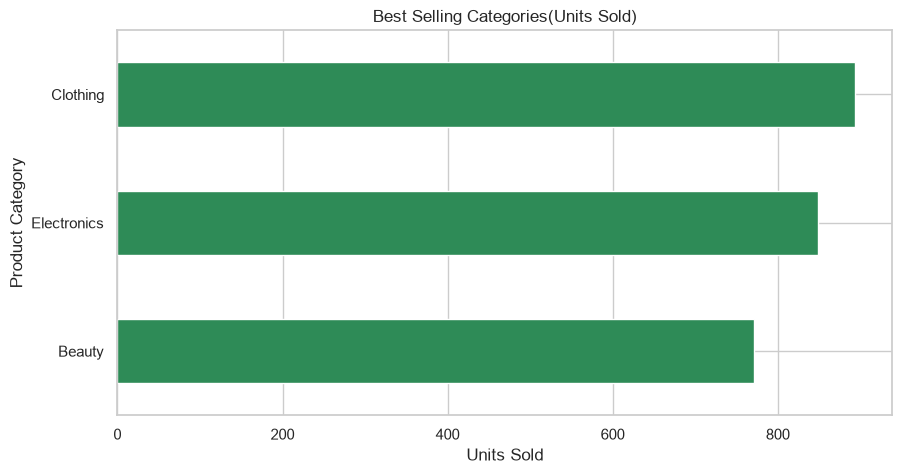

Product Category
Clothing       894
Electronics    849
Beauty         771
Name: Quantity, dtype: int64

In [14]:
# 5. Product Analysis
#I observed the dataset has no individual product names,only product category column.because of this, i cannot rank 10 separate products, instead i rank productscategories by unitsold and by revenue,which still showswhich part of the business sell best.

print(df["Product Category"].unique())
print()
units_by_category= df.groupby("Product Category")["Quantity"].sum().nlargest(10)
units_by_category.sort_values().plot(kind="barh", color="seagreen",title="Best Selling Categories(Units Sold)")
plt.xlabel("Units Sold")
plt.ylabel("Product Category")
plt.show()
units_by_category

What I found (Units Sold by Category)
-Clothing** sold the most units at  about 36% of all units
- Clothing sold about 16% more units than Beauty.
- The three categories are close together, so no single category dominates sales volume.
- Units sold only show volume. A category can sell many units but earn less money if its prices are low, so I check revenue next.

Why this matter is  clothing is the volume leader, but the business also needs to know which category earns the most money before deciding where to focus stock and marketing.

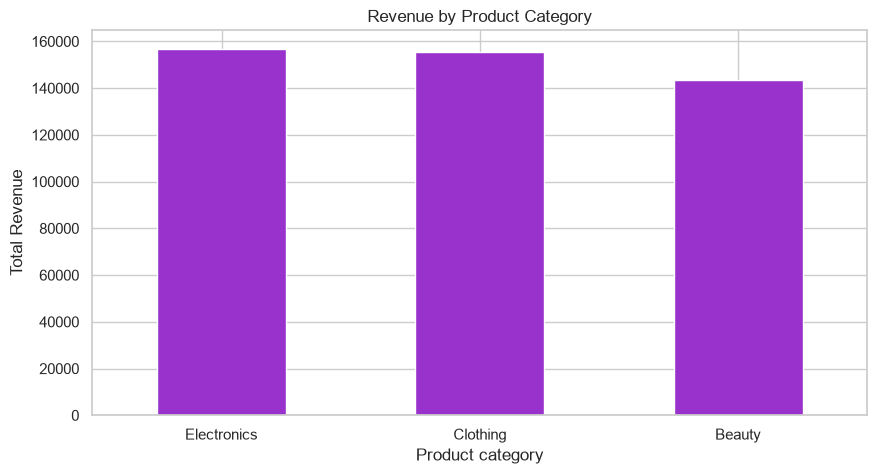

Product Category
Electronics    156905
Clothing       155580
Beauty         143515
Name: Total Amount, dtype: int64

Product Category
Electronics    34.4
Clothing       34.1
Beauty         31.5
Name: Total Amount, dtype: float64


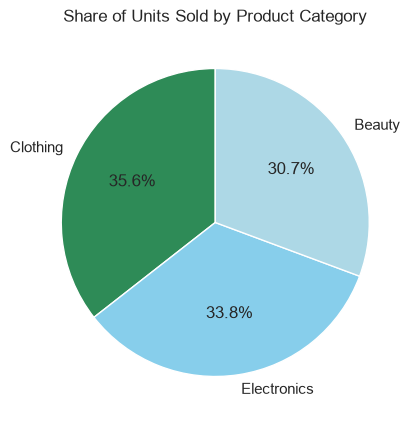

In [15]:
# total revenue per category

revenue_by_category =  df.groupby("Product Category")["Total Amount"].sum().sort_values(ascending=False)
revenue_by_category.plot(kind="bar", color="darkorchid", title="Revenue by Product Category")
plt.xlabel("Product category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.show()
print(revenue_by_category)
print()
print((revenue_by_category / revenue_by_category.sum() *100).round(1))

# Pie chart showing each category's share of units sold
units_by_category.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["seagreen", "skyblue", "lightblue"],
    title="Share of Units Sold by Product Category"
)
plt.ylabel("")
plt.show()


What I found (Revenue by Category):
- Electronics earned the most revenue about 34.4%, 
- Electronics and Clothing are only about 1,300 apart, which is less than 1%. Beauty trails Electronics by about 9%.
- The rankings differ from the units chart.Clothing sold the most units (894), but Electronics earned more revenue. This means Electronics sells at higher prices on average, while Clothing sells in higher volume at lower prices.
- Revenue is spread fairly evenly across the three categories, so no single category carries the business.

Why this matters is beacuse V\volume and revenue tell different stories. Clothing drives sales volume, while Electronics earns slightly more money per sale. The business should judge categories by both measures before deciding where to focus stock and promotions.

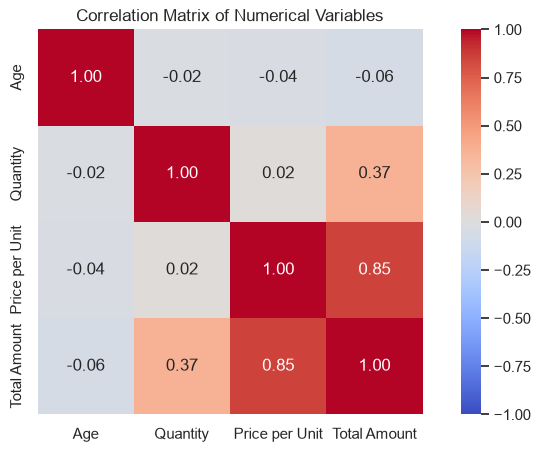

In [16]:
# 6. Correlation Heatmap
#In this section, i calculate the correlation between the numericalvariables and show it as a heatmap,a avlue close to
#+1 means two variables rise together, close to -1 means one rises as the other falls,and close to 0 means little relationship. 

corr_cols = ["Age", "Quantity", "Price per Unit", "Total Amount"]
corr = df[corr_cols].corr()
sns.heatmap(corr,annot=True, cmap="coolwarm",fmt=".2f", vmin=-1, vmax=1, square=True)
plt.title("Correlation Matrix of Numerical Variables")
plt.show()

 

What I found (Correlation Matrix)
- Price per Unit and Total Amount have a strong positive correlation (0.85). Transactions with higher unit prices tend to have much higher totals.
- Quantity and Total Amount have a moderate positive correlation (0.37).Buying more units raises the total, but less strongly than price does.
- This is expected, because Total Amount is calculated as Quantity × Price per Unit. Price drives the total more because it varies far more (25 to 500) than quantity does (1 to 4).
- Age has almost no correlation with anything
- Quantity and Price per Unit are practically uncorrelated (0.02)

Why this matters: Revenue depends mainly on the price level of what is sold, not on customer age. Targeting customers by age alone is unlikely to raise sales, so the business should focus on product pricing and mix instead.

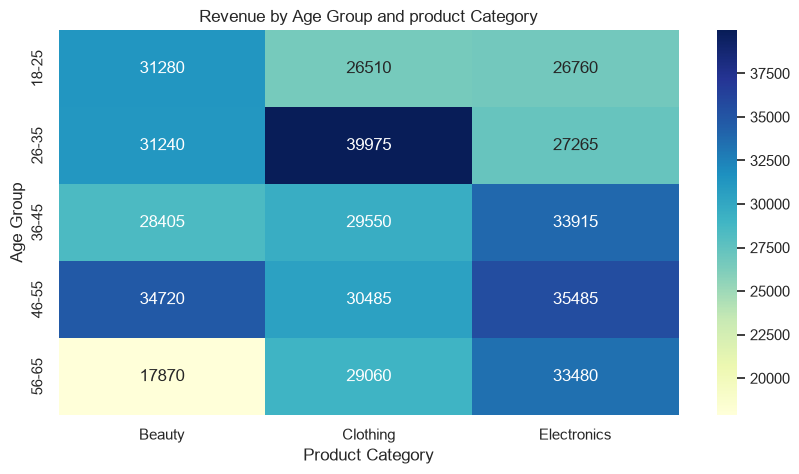

In [17]:
# 7. Additional Visualization: revenue by age group and product category
#The correlation analysis showed that age has almost no relationship with total spending. Here I check whether age affects  
# which categories customers spend on, by showing revenue for every combination of age group and product category.

age_cat = df.pivot_table(
index="Age Group",
columns= "Product Category",
values="Total Amount",
aggfunc="sum",
observed=False
)
sns.heatmap(age_cat,annot=True,fmt=".0f", cmap="YlGnBu")
plt.title("Revenue by Age Group and product Category")
plt.xlabel("Product Category")
plt.ylabel("Age Group")
plt.show()









What I found (Revenue by Age Group and Product Category)
- The strongest combination is Clothing among 26-35 year olds (39,975), which is about 26% of all Clothing revenue and clearly the darkest square on the grid. No other age group spends more than about 30,500 on Clothing.
- The weakest combination is Beauty among 56-65 year olds (17,870), about 43% lower than the 18-25 group's Beauty revenue (31,280). Beauty does best among 46-55 year olds (34,720).
- Electronics sells more to older customers.Customers aged 36 and above spend roughly 33,500 to 35,500 on Electronics, compared with about 27,000 for those under 36.
- The correlation analysis showed that age has almost no link to total spending. This grid shows that age still matters for what people buy,different age groups favour different categories.
- Note: each square is based on a small number of transactions (about 65-75 each), so these patterns are worth testing with more data.

Why this matters: The business can target by category instead of by overall spend: Clothing campaigns for 26-35 year olds, Electronics promotions for customers over 36, and Beauty offers for the 46-55 group. The 56-65 group buys little Beauty, so it needs a different approach or lower priority for that category.

## 9. Conclusion and Recommendations

## Key Findings
- The dataset has 1,000 transactions covering 2023, with total revenue of 456,000.
- Sales are volatile, not steadily growing: May was the strongest month (about 53,000) and September the weakest (about 23,500). Q4 was the strongest quarter and Q3 the weakest.
- Customers are spread evenly across age groups and almost evenly by gender (51% female, 49% male).
- Revenue is split closely across categories: Electronics earned the most (156,905), Clothing sold the most units (894) and Beauty was lowest on both measures.
- Price per Unit drives revenue (correlation 0.85 with Total Amount), while age has almost no link to total spending.
- The typical sale is small (median 135) but a few large purchases (up to 2,000) lift the average to 456.
- Age does influence what people buy: Clothing sells best to 26-35 year olds, and Beauty sells poorly to 56-65 year olds.

### Recommendations
1. **Run targeted promotions in the weak months and quarters.** September and Q3 are the main slump. Offering discounts, bundles or campaigns then could lift revenue, and the business should study what worked in May, October and December and repeat it.
2. **Market by age and category, not by age alone.** Promote Clothing to 26-35 year olds, Electronics to customers aged 36 and above, and Beauty to the 46-55 group. Beauty needs a different approach for the 56-65 group, such as products designed for them.
3. **Focus on higher-priced products and upselling.** Because unit price has the strongest link to revenue, a few more premium items or "upgrade" offers will raise revenue more than trying to get customers to buy extra units.
4. **Do not plan around the average sale.** The median sale (135) is far below the mean (456), so a small number of high-value purchases carry a large share of revenue. The business should protect those big-ticket customers, for example with loyalty offers.
5. **Do not split marketing by gender.** The customer base is balanced, so gender-specific campaigns are unlikely to help. A better focus is the product and age patterns above.

### Limitations
The dataset covers one year and 1,000 transactions, has no individual product names, and the age-and-category squares each rest on only 65-75 transactions. These patterns should be confirmed with more data before making large business decisions.